# Análisis de Cambio Porcentual de Pesos

El objetivo de este análisis es determinar si el cambio porcentual en el peso de las semillas depende más del **peso inicial** (`pre_weight`) o del **tratamiento** (`treatment_floor`).

In [3]:
import pandas as pd
import glob
import os
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf

# Ruta a la carpeta de experimentos
experiments_dir = '../data/experiments'

# Buscar todos los archivos trays.csv en subcarpetas YYYYMMDD
csv_files = glob.glob(os.path.join(experiments_dir, '[0-9]*', 'trays.csv'))

df_list = []
for file in csv_files:
    df = pd.read_csv(file)
    # Extraer la fecha de la carpeta
    date_str = os.path.basename(os.path.dirname(file))
    df['experiment_date'] = date_str
    df_list.append(df)

all_data = pd.concat(df_list, ignore_index=True)

print(f"Se cargaron {len(all_data)} registros en total.")
all_data.head()

Se cargaron 174 registros en total.


,tray_id,exp_id,treatment_floor,floor,position,pre_weight,post_weight,experiment_date,water_ml
0,20260331_A1,20260331,2,A,1,3.813,5.817,20260331,NaN
1,20260331_A2,20260331,3,A,2,3.467,5.354,20260331,NaN
2,20260331_A3,20260331,4,A,3,3.628,5.884,20260331,NaN
3,20260331_A4,20260331,6,A,4,3.794,5.927,20260331,NaN
4,20260331_A5,20260331,8,A,5,3.856,5.964,20260331,NaN


In [4]:
# Calcular cambio porcentual
all_data['pct_change'] = (all_data['post_weight'] - all_data['pre_weight']) / all_data['pre_weight']

all_data.head()

,tray_id,exp_id,treatment_floor,floor,position,pre_weight,post_weight,experiment_date,water_ml,pct_change
0,20260331_A1,20260331,2,A,1,3.813,5.817,20260331,NaN,0.525570
1,20260331_A2,20260331,3,A,2,3.467,5.354,20260331,NaN,0.544275
2,20260331_A3,20260331,4,A,3,3.628,5.884,20260331,NaN,0.621830
3,20260331_A4,20260331,6,A,4,3.794,5.927,20260331,NaN,0.562203
4,20260331_A5,20260331,8,A,5,3.856,5.964,20260331,NaN,0.546680


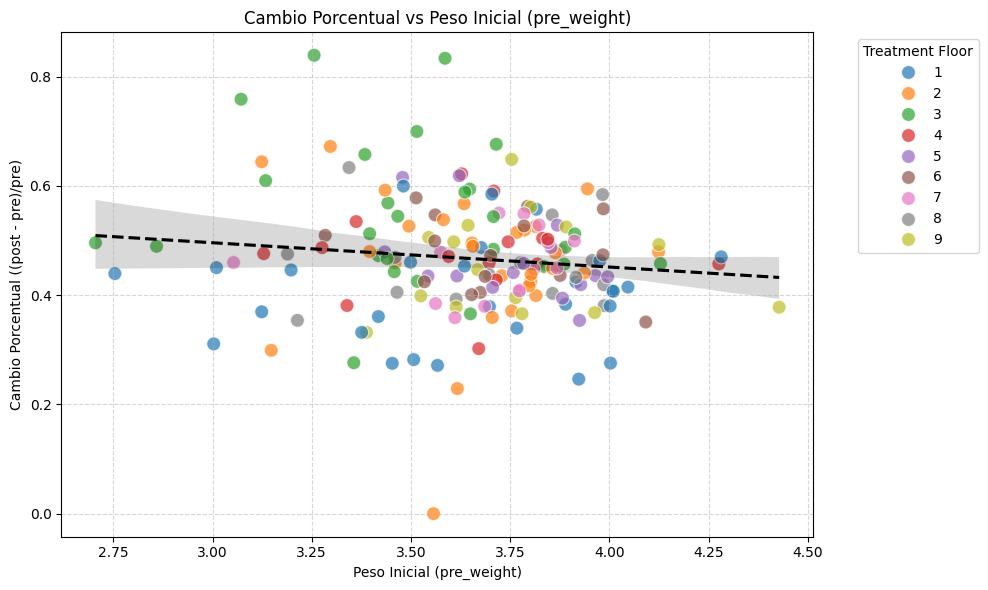

In [5]:
# Graficar Cambio Porcentual vs Peso Inicial (pre_weight)
plt.figure(figsize=(10, 6))

# Usamos scatter plot, diferenciando por tratamiento (treatment_floor)
sns.scatterplot(data=all_data, x='pre_weight', y='pct_change', hue='treatment_floor', palette='tab10', s=100, alpha=0.7)

# Añadir línea de tendencia general
sns.regplot(data=all_data, x='pre_weight', y='pct_change', scatter=False, color='black', line_kws={'linestyle': '--', 'label': 'Tendencia general'})

plt.title('Cambio Porcentual vs Peso Inicial (pre_weight)')
plt.xlabel('Peso Inicial (pre_weight)')
plt.ylabel('Cambio Porcentual ((post - pre)/pre)')
plt.legend(title='Treatment Floor', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### Análisis Estadístico

Para determinar si el mayor cambio se debe a diferencias en los pesos iniciales o al tratamiento aplicado, corremos una regresión lineal (ANCOVA) usando `pct_change` como variable dependiente, `pre_weight` como covariable y `treatment_floor` como factor categórico.

In [6]:
# Tratamos treatment_floor como variable categórica
model = smf.ols('pct_change ~ pre_weight + C(treatment_floor)', data=all_data).fit()

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:             pct_change   R-squared:                       0.155
Model:                            OLS   Adj. R-squared:                  0.109
Method:                 Least Squares   F-statistic:                     3.345
Date:                Thu, 18 Jun 2026   Prob (F-statistic):           0.000877
Time:                        19:03:16   Log-Likelihood:                 159.57
No. Observations:                 174   AIC:                            -299.1
Df Residuals:                     164   BIC:                            -267.5
Df Model:                           9                                         
Covariance Type:            nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------
Intercept                 

### Comparación del Peso Inicial (pre_weight) por Piso y Fecha

A continuación visualizamos la distribución de los pesos iniciales de las semillas para cada piso (treatment_floor), enfocándonos en los experimentos de marzo (`20260331`) y junio (`20260608`). Esto permite verificar si hubo diferencias sistemáticas de peso al momento de iniciar los experimentos.

/var/folders/ll/hm35mj650fs_spb22x5qqnqh0000gn/T/ipykernel_22356/1424538958.py:16: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(


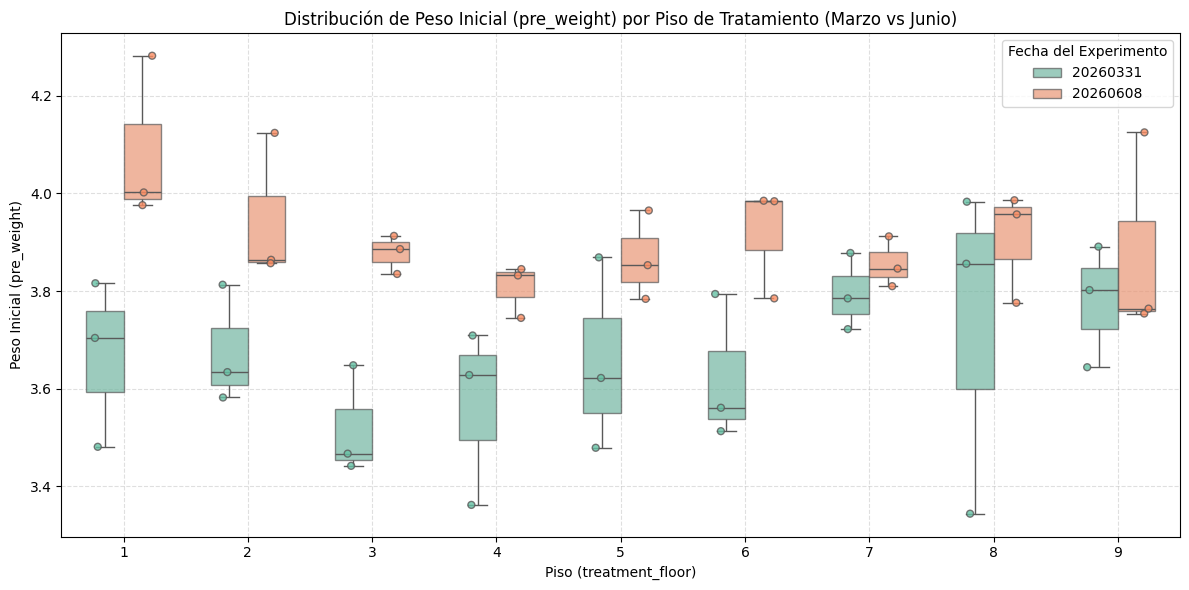

In [7]:
fechas_interes = ['20260331', '20260608']
df_filtrado = all_data[all_data['experiment_date'].isin(fechas_interes)].copy()

plt.figure(figsize=(12, 6))
sns.boxplot(
    data=df_filtrado,
    x='treatment_floor',
    y='pre_weight',
    hue='experiment_date',
    palette='Set2',
    width=0.6,
    boxprops={"alpha": 0.7}
)

# Añadimos también los puntos individuales para ver la distribución real
sns.stripplot(
    data=df_filtrado,
    x='treatment_floor',
    y='pre_weight',
    hue='experiment_date',
    palette='Set2',
    dodge=True,
    alpha=0.8,
    linewidth=1,
    edgecolor='gray'
)

plt.title('Distribución de Peso Inicial (pre_weight) por Piso de Tratamiento (Marzo vs Junio)')
plt.xlabel('Piso (treatment_floor)')
plt.ylabel('Peso Inicial (pre_weight)')

# Ajustar leyenda (stripplot duplica las etiquetas)
handles, labels = plt.gca().get_legend_handles_labels()
plt.legend(handles[:2], labels[:2], title='Fecha del Experimento')
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()
